# Лабораторна робота 7 — класифікація Fashion-MNIST

**Мета:** підготувати зображення та мітки, навчити Dense-мережі й пояснити їхні помилки. **Варіант 7:** змінити лише `batch_size` з 128 на 64.

Джерело: [Fashion-MNIST](https://github.com/zalandoresearch/fashion-mnist), ліцензія MIT. Перше завантаження потребує інтернету. Результати зберігаються у `Lab7`.

**Повторний запуск:** потрібен Python, сумісний із TensorFlow для macOS x86 (цей запуск виконано з Python 3.9 і TensorFlow 2.16.2). Наявний `.venv` з Python 3.14 не містить TensorFlow.

## 1. Імпорт і версії

Встановлюємо seed для відтворюваності. Папка `artifacts` міститиме checkpoint і модель, `figures` — рисунки.

In [1]:
import json
import platform
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from tensorflow import keras
from tensorflow.keras import layers

SEED, VARIANT = 42, 7
keras.utils.set_random_seed(SEED)
LAB_DIR = Path.cwd() if Path.cwd().name == "Lab7" else Path.cwd() / "Lab7"
assert LAB_DIR.is_dir(), "Запустіть ноутбук із папки Lab7 або кореня репозиторію."
ARTIFACTS, FIGURES = LAB_DIR / "artifacts", LAB_DIR / "figures"
ARTIFACTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
package_versions = {n: version(n) for n in
                    ("tensorflow", "numpy", "pandas", "matplotlib", "scikit-learn")}
print("Python", platform.python_version(), "пакети", package_versions)

2026-11-03 12:32:57.508293: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


/private/tmp/lab7-py39/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Python 3.9.6 пакети {'tensorflow': '2.16.2', 'numpy': '1.26.4', 'pandas': '2.3.3', 'matplotlib': '3.9.4', 'scikit-learn': '1.6.1'}


## 2. Дані та поділ

Офіційний test зберігаємо для фінальної перевірки. Індекси 60 000 інших прикладів ділимо стратифіковано на train/validation 80/20. Порядок класів відповідає міткам 0–9.

In [2]:
(x_dev, y_dev), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
class_names = ["Футболка або топ", "Штани", "Светр", "Сукня", "Пальто",
               "Сандалі", "Сорочка", "Кросівки", "Сумка", "Черевики"]
train_idx, val_idx = train_test_split(
    np.arange(len(y_dev)), test_size=0.20, stratify=y_dev, random_state=SEED
)
x_train, y_train = x_dev[train_idx], y_dev[train_idx]
x_val, y_val = x_dev[val_idx], y_dev[val_idx]
for name, x, y, n in (("train", x_train, y_train, 48000),
                      ("validation", x_val, y_val, 12000),
                      ("test", x_test, y_test, 10000)):
    assert x.shape == (n, 28, 28) and y.shape == (n,)
    assert np.issubdtype(x.dtype, np.integer) and 0 <= x.min() <= x.max() <= 255
    assert set(np.unique(y)) == set(range(10))
    print(f"{name}: {x.shape}, {x.dtype}, pixels {x.min()}..{x.max()}")
assert not np.intersect1d(train_idx, val_idx).size
counts = pd.DataFrame(
    {n: np.bincount(y, minlength=10) for n, y in
     (("train", y_train), ("validation", y_val), ("test", y_test))},
    index=class_names,
)
counts.index.name = "Клас"
display(counts)

    0/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step


       0/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

   49152/26421880 ━━━━━━━━━━━━━━━━━━━━ 1:10 3us/step

   81920/26421880 ━━━━━━━━━━━━━━━━━━━━ 1:19 3us/step

  147456/26421880 ━━━━━━━━━━━━━━━━━━━━ 55s 2us/step 

... (76 outputs left out)

3563520/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


train: (48000, 28, 28), uint8, pixels 0..255
validation: (12000, 28, 28), uint8, pixels 0..255
test: (10000, 28, 28), uint8, pixels 0..255


,train,validation,test
Клас,,,
Футболка або топ,4800,1200,1000
Штани,4800,1200,1000
Светр,4800,1200,1000
Сукня,4800,1200,1000
Пальто,4800,1200,1000
Сандалі,4800,1200,1000
Сорочка,4800,1200,1000
Кросівки,4800,1200,1000
Сумка,4800,1200,1000


Показуємо одне **навчальне** зображення для кожної мітки — це перевірка відповідності назв і числових кодів.

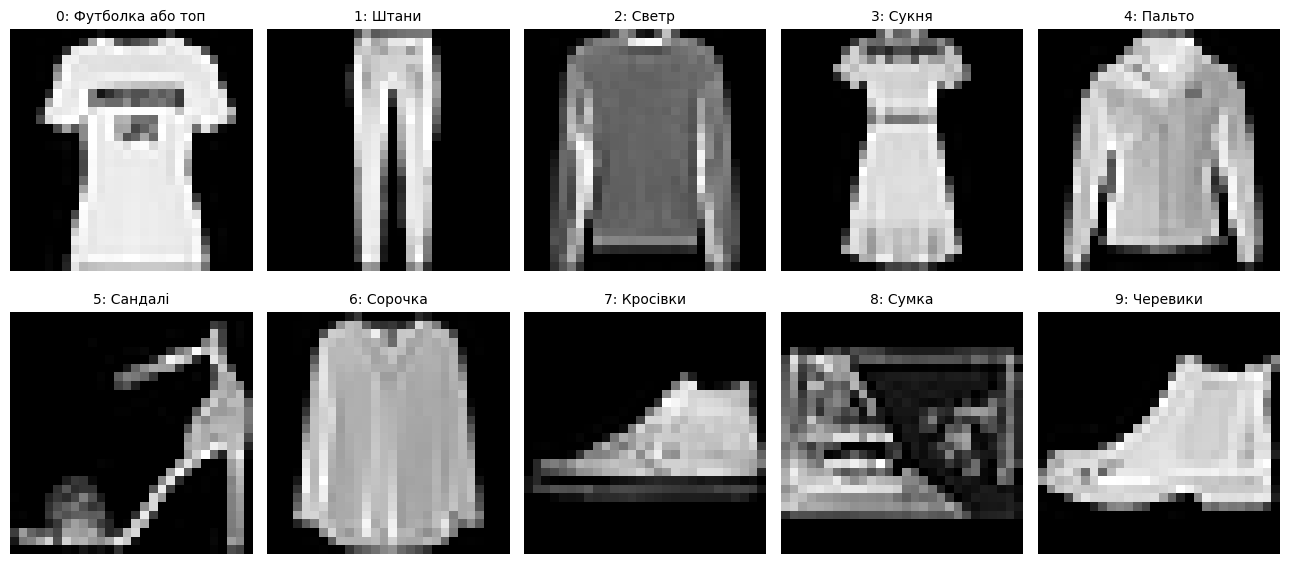

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(13, 6))
for k, ax in enumerate(axes.flat):
    ax.imshow(x_train[np.flatnonzero(y_train == k)[0]], cmap="gray")
    ax.set_title(f"{k}: {class_names[k]}", fontsize=10)
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIGURES / "class_examples.png", dpi=160, bbox_inches="tight")
plt.show()

## 3. Підготовка та Dummy baseline

Переводимо зображення у `float32`, залишаючи шкалу 0–255. Нормалізацію один раз зробить шар `Rescaling` усередині моделі. Dummy завжди обирає найчастіший клас і не розпізнає пікселі.

In [4]:
x_train, x_val, x_test = (x.astype("float32") for x in
                          (x_train, x_val, x_test))
for x in (x_train, x_val, x_test):
    assert x.shape[1:] == (28, 28) and x.dtype == np.float32
    assert np.isfinite(x).all() and 0 <= x.min() <= x.max() <= 255
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(x_train.reshape(len(x_train), -1), y_train)
dummy_val_pred = dummy.predict(x_val.reshape(len(x_val), -1))
dummy_val_accuracy = accuracy_score(y_val, dummy_val_pred)
dummy_val_f1 = f1_score(y_val, dummy_val_pred, average="macro", zero_division=0)
print(f"Dummy validation: accuracy={dummy_val_accuracy:.4f}, macro-F1={dummy_val_f1:.4f}")

Dummy validation: accuracy=0.1000, macro-F1=0.0182


## 4. Базова мережа та варіант 7

`Flatten` дає 784 входи без навчених ваг; прихований шар має 128 нейронів ReLU; десять виходів softmax відповідають класам. Індексні мітки узгоджено зі `SparseCategoricalCrossentropy(from_logits=False)`. Архітектура й Adam(0.001) однакові; змінюється тільки batch size.

In [5]:
def build_model():
    model = keras.Sequential([
        layers.Input(shape=(28, 28)), layers.Rescaling(1.0 / 255),
        layers.Flatten(), layers.Dense(128, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=False),
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
    )
    return model

keras.utils.set_random_seed(SEED)
print("Базова мережа:")
build_model().summary()
keras.utils.set_random_seed(SEED)
print("Варіант 7 (та сама архітектура):")
build_model().summary()

Базова мережа:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

... (2 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Для кожного запуску створюємо **нову модель**, знову встановлюємо seed та використовуємо окремий checkpoint. EarlyStopping має patience 4; найкращу епоху визначає `val_loss`. Test на цьому кроці не використовується.

In [6]:
def train_model(name, batch_size):
    keras.utils.set_random_seed(SEED)
    model = build_model()
    checkpoint = ARTIFACTS / f"{name}_best.keras"
    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=4, restore_best_weights=True
        ),
        keras.callbacks.ModelCheckpoint(
            str(checkpoint), monitor="val_loss", save_best_only=True
        ),
    ]
    history = model.fit(
        x_train, y_train, validation_data=(x_val, y_val),
        epochs=30, batch_size=batch_size, callbacks=callbacks, verbose=2
    )
    best_epoch = int(np.argmin(history.history["val_loss"]) + 1)
    print(name, "епох:", len(history.epoch), "найкраща:", best_epoch)
    return keras.models.load_model(checkpoint), history, best_epoch

base_best, base_history, base_epoch = train_model("base", 128)
variant_best, variant_history, variant_epoch = train_model("variant7", 64)

Epoch 1/30


375/375 - 2s - 5ms/step - accuracy: 0.7988 - loss: 0.5887 - val_accuracy: 0.8217 - val_loss: 0.4879


Epoch 2/30


375/375 - 1s - 3ms/step - accuracy: 0.8515 - loss: 0.4202 - val_accuracy: 0.8403 - val_loss: 0.4431


Epoch 3/30


375/375 - 1s - 3ms/step - accuracy: 0.8662 - loss: 0.3768 - val_accuracy: 0.8532 - val_loss: 0.4090


... (56 outputs left out)

750/750 - 2s - 3ms/step - accuracy: 0.9159 - loss: 0.2288 - val_accuracy: 0.8904 - val_loss: 0.3199


Epoch 13/30


750/750 - 2s - 3ms/step - accuracy: 0.9191 - loss: 0.2208 - val_accuracy: 0.8906 - val_loss: 0.3220


variant7 епох: 13 найкраща: 9


Порівнюємо train/validation loss та accuracy. Accuracy може лишатися незмінною, поки loss змінюється: класи `argmax` ті самі, але ймовірності правильних класів інші.

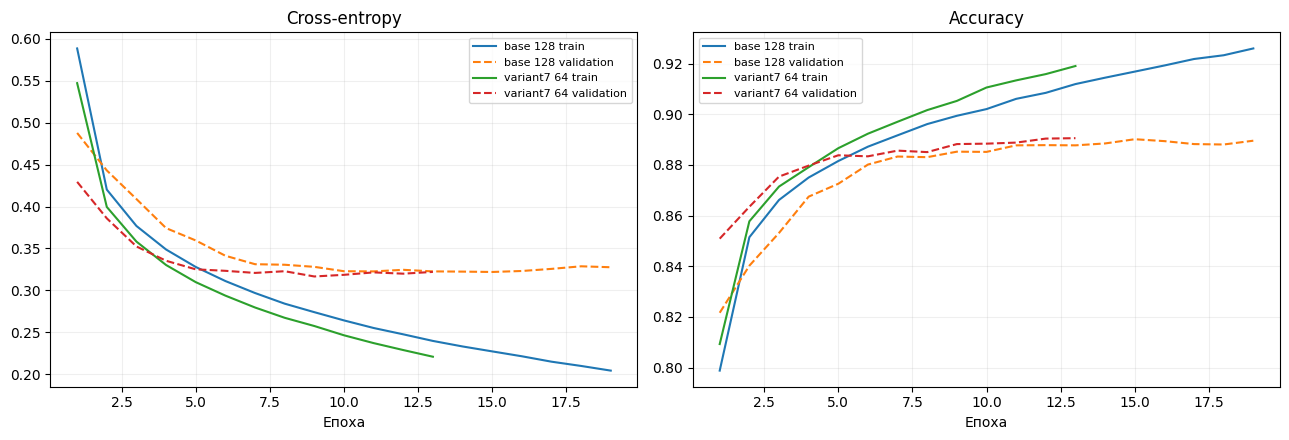

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, h in (("base 128", base_history), ("variant7 64", variant_history)):
    e = np.arange(1, len(h.epoch) + 1)
    for ax, key in zip(axes, ("loss", "accuracy")):
        ax.plot(e, h.history[key], label=f"{name} train")
        ax.plot(e, h.history["val_" + key], "--", label=f"{name} validation")
for ax, title in zip(axes, ("Cross-entropy", "Accuracy")):
    ax.set(title=title, xlabel="Епоха")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "training_curves.png", dpi=160, bbox_inches="tight")
plt.show()

## 5. Індексні та one-hot мітки

На п’яти тих самих validation-прогнозах перевіряємо, що sparse і звичайна категорійна крос-ентропія збігаються. Навчання повторно не виконуємо.

In [8]:
p5 = base_best(x_val[:5], training=False).numpy()
onehot = keras.utils.to_categorical(y_val[:5], num_classes=10)
loss_sparse = keras.losses.SparseCategoricalCrossentropy(from_logits=False)(
    y_val[:5], p5
)
loss_onehot = keras.losses.CategoricalCrossentropy(from_logits=False)(
    onehot, p5
)
np.testing.assert_allclose(loss_sparse.numpy(), loss_onehot.numpy(), rtol=1e-5)
print("Sparse:", float(loss_sparse.numpy()), "one-hot:", float(loss_onehot.numpy()))

Sparse: 0.07077164202928543 one-hot: 0.07077133655548096


## 6. Вибір за validation і фінальний test

Спершу порівнюємо **завантажені checkpoint** за чистою крос-ентропією на validation, а також показуємо accuracy і macro-F1. За рівності loss залишаємо базову модель. Лише після фіксації вибору оцінюємо test.

In [9]:
def checked_probabilities(model, x):
    p = model.predict(x, batch_size=256, verbose=0)
    assert p.shape == (len(x), 10)
    assert np.isfinite(p).all() and np.all((p >= 0) & (p <= 1))
    np.testing.assert_allclose(p.sum(axis=1), 1, atol=1e-5)
    return p

def metrics(y, p):
    return {
        "cross_entropy": float(keras.losses.SparseCategoricalCrossentropy(
            from_logits=False
        )(y, p).numpy()),
        "accuracy": float(accuracy_score(y, p.argmax(axis=1))),
        "macro_f1": float(f1_score(
            y, p.argmax(axis=1), average="macro", zero_division=0
        )),
    }

models = {"base": base_best, "variant7": variant_best}
val_prob = {n: checked_probabilities(m, x_val) for n, m in models.items()}
val_metrics = {n: metrics(y_val, p) for n, p in val_prob.items()}
selected_name = (
    "variant7" if val_metrics["variant7"]["cross_entropy"]
    < val_metrics["base"]["cross_entropy"] else "base"
)
selected_model = models[selected_name]
display(pd.DataFrame(val_metrics).T)
print("Рішення за validation cross-entropy:", selected_name)

,cross_entropy,accuracy,macro_f1
base,0.321113,0.890167,0.890769
variant7,0.315586,0.888250,0.888531


Рішення за validation cross-entropy: variant7


In [10]:
# Test оцінюємо після фіксації selected_name.
dummy_test_pred = dummy.predict(x_test.reshape(len(x_test), -1))
test_prob = {n: checked_probabilities(m, x_test) for n, m in models.items()}
test_metrics = {n: metrics(y_test, p) for n, p in test_prob.items()}
rows = [{
    "model": "dummy", "validation_cross_entropy": np.nan,
    "validation_accuracy": dummy_val_accuracy,
    "validation_macro_f1": dummy_val_f1,
    "test_cross_entropy": np.nan,
    "test_accuracy": accuracy_score(y_test, dummy_test_pred),
    "test_macro_f1": f1_score(
        y_test, dummy_test_pred, average="macro", zero_division=0
    ),
    "epochs": np.nan, "best_epoch": np.nan, "selected": False,
}]
for name, h, best_epoch in (
    ("base", base_history, base_epoch),
    ("variant7", variant_history, variant_epoch),
):
    rows.append({
        "model": name,
        **{"validation_" + k: v for k, v in val_metrics[name].items()},
        **{"test_" + k: v for k, v in test_metrics[name].items()},
        "epochs": len(h.epoch), "best_epoch": best_epoch,
        "selected": name == selected_name,
    })
comparison = pd.DataFrame(rows)
display(comparison.round(4))
comparison.to_csv(LAB_DIR / "model_comparison.csv", index=False)

,model,validation_cross_entropy,validation_accuracy,validation_macro_f1,test_cross_entropy,test_accuracy,test_macro_f1,epochs,best_epoch,selected
0,dummy,NaN,0.1000,0.0182,NaN,0.1000,0.0182,NaN,NaN,False
1,base,0.3211,0.8902,0.8908,0.3533,0.8780,0.8786,19.0,15.0,False
2,variant7,0.3156,0.8882,0.8885,0.3455,0.8759,0.8761,13.0,9.0,True


## 7. Аналіз помилок

У матриці рядки — фактичні класи, стовпці — прогнозовані. Precision — частка правильних прогнозів класу, recall — частка знайдених представників класу, F1 — їх гармонійне середнє. Macro-F1 усереднює F1 десяти класів порівну.

,precision,recall,f1-score,support
Футболка або топ,0.840,0.813,0.826,1000.000
Штани,0.984,0.970,0.977,1000.000
Светр,0.738,0.842,0.787,1000.000
Сукня,0.880,0.889,0.885,1000.000
Пальто,0.832,0.728,0.777,1000.000
Сандалі,0.970,0.961,0.965,1000.000
Сорочка,0.670,0.682,0.676,1000.000
Кросівки,0.921,0.974,0.947,1000.000
Сумка,0.972,0.966,0.969,1000.000
Черевики,0.973,0.934,0.953,1000.000


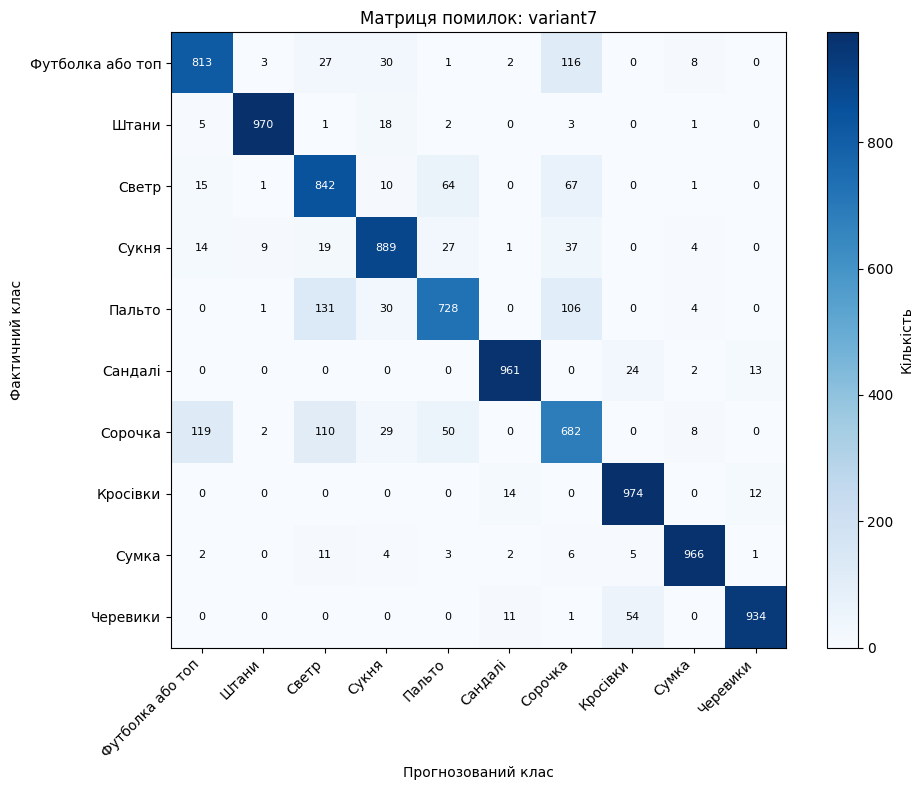

Найчастіша плутанина: Пальто → Светр (131).
Пальто: precision=0.832, recall=0.728, F1=0.777
Светр: precision=0.738, recall=0.842, F1=0.787


In [11]:
probabilities = test_prob[selected_name]
pred = probabilities.argmax(axis=1)
confidence = probabilities.max(axis=1)
cm = confusion_matrix(y_test, pred, labels=np.arange(10))
report = pd.DataFrame(classification_report(
    y_test, pred, labels=np.arange(10), target_names=class_names,
    zero_division=0, output_dict=True
)).T
display(report.round(3))
report.to_csv(LAB_DIR / "classification_report.csv")

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(cm, cmap="Blues")
fig.colorbar(im, ax=ax, label="Кількість")
ax.set(xticks=np.arange(10), yticks=np.arange(10),
       xticklabels=class_names, yticklabels=class_names,
       xlabel="Прогнозований клас", ylabel="Фактичний клас",
       title=f"Матриця помилок: {selected_name}")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max()/2 else "black", fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "confusion_matrix.png", dpi=160, bbox_inches="tight")
plt.show()
offdiag = cm.copy()
np.fill_diagonal(offdiag, 0)
actual, predicted = np.unravel_index(offdiag.argmax(), offdiag.shape)
print(f"Найчастіша плутанина: {class_names[actual]} → "
      f"{class_names[predicted]} ({offdiag[actual, predicted]}).")
for k in (actual, predicted):
    r = report.loc[class_names[k]]
    print(f"{class_names[k]}: precision={r['precision']:.3f}, "
          f"recall={r['recall']:.3f}, F1={r['f1-score']:.3f}")

Показуємо до п’яти найвпевненіших помилок із правильним класом, прогнозом, максимальною оцінкою та оцінкою правильного класу. Висока softmax-оцінка не гарантує правильності.

Помилок: 1241


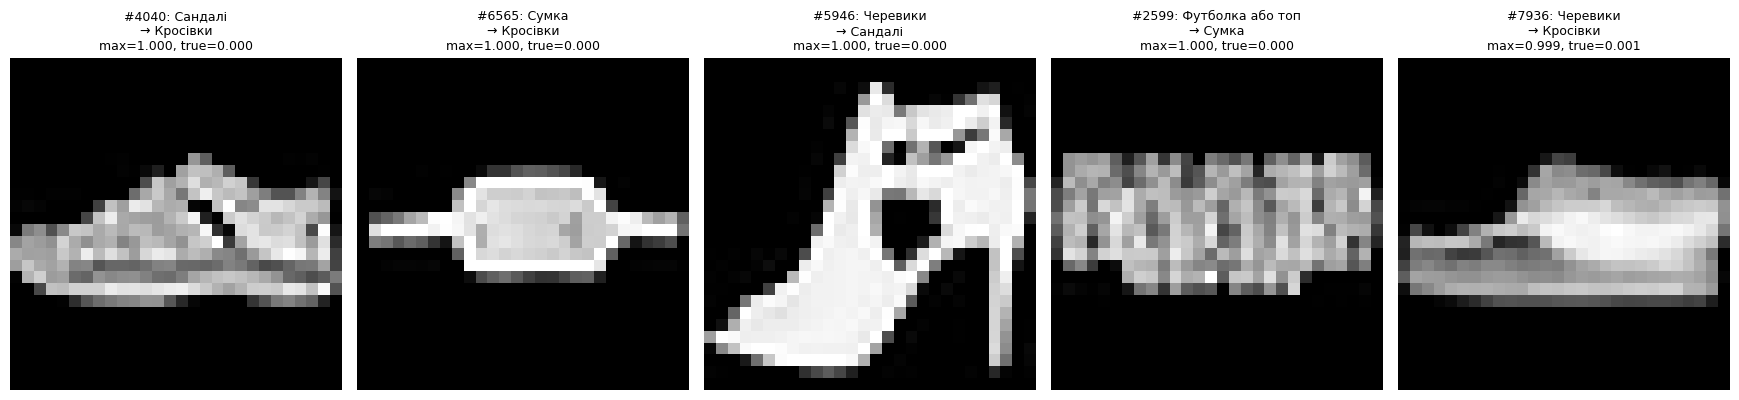

In [12]:
wrong = np.flatnonzero(pred != y_test)
order = wrong[np.argsort(confidence[wrong])[::-1]]
show_ids = order[:5]
print("Помилок:", len(wrong))
if len(show_ids):
    fig, axes = plt.subplots(1, len(show_ids), figsize=(3.5*len(show_ids), 4))
    for i, ax in zip(show_ids, np.atleast_1d(axes)):
        ax.imshow(x_test[i], cmap="gray")
        ax.set_title(
            f"#{i}: {class_names[y_test[i]]}\n→ {class_names[pred[i]]}\n"
            f"max={confidence[i]:.3f}, true={probabilities[i, y_test[i]]:.3f}",
            fontsize=9,
        )
        ax.axis("off")
    fig.tight_layout()
    fig.savefig(FIGURES / "confident_errors.png", dpi=160, bbox_inches="tight")
    plt.show()

Для одного правильного й одного хибного прогнозу показуємо всі десять оцінок. `argmax` завжди вибирає найбільшу, навіть якщо вона нижча за 0.5; поріг 0.5 тут не є правилом вибору класу.

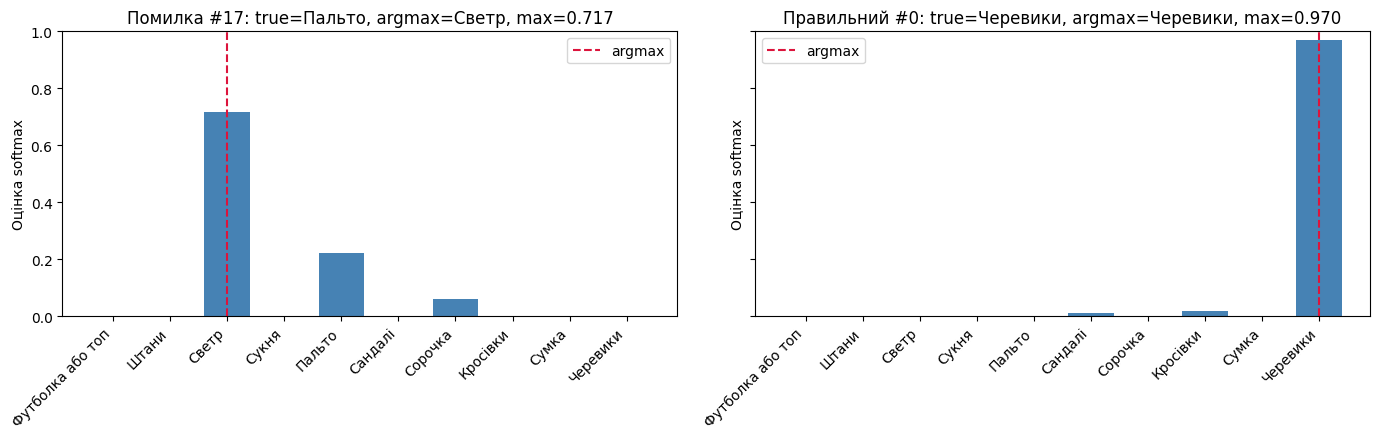

Випадків із max softmax < 0.5: 416
Приклад #66: argmax=Сорочка, max=0.331


In [13]:
correct = np.flatnonzero(pred == y_test)
if len(wrong) and len(correct):
    examples = [(int(wrong[0]), "Помилка"), (int(correct[0]), "Правильний")]
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
    for ax, (i, label) in zip(axes, examples):
        ax.bar(range(10), probabilities[i], color="steelblue")
        ax.axvline(pred[i], color="crimson", linestyle="--", label="argmax")
        ax.set(xticks=range(10), xticklabels=class_names, ylim=(0, 1),
               ylabel="Оцінка softmax",
               title=f"{label} #{i}: true={class_names[y_test[i]]}, "
                     f"argmax={class_names[pred[i]]}, max={confidence[i]:.3f}")
        ax.legend()
        plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    fig.tight_layout()
    fig.savefig(FIGURES / "probability_examples.png", dpi=160, bbox_inches="tight")
    plt.show()
low = np.flatnonzero(confidence < 0.5)
print("Випадків із max softmax < 0.5:", len(low))
if len(low):
    i = int(low[0])
    print(f"Приклад #{i}: argmax={class_names[pred[i]]}, max={confidence[i]:.3f}")

## 8. Збереження і перевірка

Модель містить шар `Rescaling`, тож окремий препроцесор не потрібен. Метадані фіксують класи, форму й шкалу входу, seed, індекси поділу, варіант, критерій вибору та версії. Один validation-зразок зберігаємо для перевірки після перезапуску ядра.

In [14]:
final_path = ARTIFACTS / "lab7_model.keras"
selected_model.save(final_path)
metadata = {
    "dataset": "Fashion-MNIST",
    "dataset_url": "https://github.com/zalandoresearch/fashion-mnist",
    "dataset_license": "MIT",
    "class_names": class_names,
    "input_shape": [28, 28], "input_dtype": "float32",
    "input_range": [0, 255], "rescaling_inside_model": True,
    "seed": SEED, "variant": VARIANT,
    "variant_change": "batch_size=64 (base: 128)",
    "selection_criterion": "minimum validation cross-entropy; base wins exact tie",
    "selected_model": selected_name,
    "train_indices_in_official_development_set": train_idx.tolist(),
    "validation_indices_in_official_development_set": val_idx.tolist(),
    "official_test_unchanged": True,
    "python_version": platform.python_version(),
    "package_versions": package_versions,
}
(LAB_DIR / "metadata.json").write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8"
)
np.save(ARTIFACTS / "probe_image.npy", x_val[0])
probe = x_val[:3]
before = selected_model(probe, training=False).numpy()
restored = keras.models.load_model(final_path)
after = restored(probe, training=False).numpy()
np.testing.assert_allclose(before, after, rtol=1e-5, atol=1e-6)
print("Збережено:", final_path, "прогнози до/після завантаження збігаються.")

Збережено: /Users/staslulko/Documents/GitHub/data-mining/Lab7/artifacts/lab7_model.keras прогнози до/після завантаження збігаються.


Наступну клітинку можна виконати **окремо після Restart Kernel**. Вона завантажує метадані, модель і зразок, додає batch-вимір та повертає назву прогнозованого класу.

In [15]:
import json
from pathlib import Path
import numpy as np
from tensorflow import keras

lab_dir = Path.cwd() if Path.cwd().name == "Lab7" else Path.cwd() / "Lab7"
saved_metadata = json.loads((lab_dir / "metadata.json").read_text(encoding="utf-8"))
saved_model = keras.models.load_model(lab_dir / "artifacts" / "lab7_model.keras")
image = np.load(lab_dir / "artifacts" / "probe_image.npy").astype("float32")
assert image.shape == tuple(saved_metadata["input_shape"])
scores = saved_model(image[None, ...], training=False).numpy()[0]
class_id = int(scores.argmax())
print(f"Клас: {class_id} — {saved_metadata['class_names'][class_id]}; "
      f"оцінка: {scores[class_id]:.3f}")

Клас: 5 — Сандалі; оцінка: 0.988


## Висновок

Цей висновок формується з фактичних чисел після запуску. Вибір здійснено за validation cross-entropy; test використано тільки для фінального оцінювання. Результати стосуються зображень Fashion-MNIST 28×28 у шкалі 0–255.

In [16]:
from IPython.display import Markdown, display

chosen = comparison.loc[comparison.model == selected_name].iloc[0]
base_row = comparison.loc[comparison.model == "base"].iloc[0]
variant_row = comparison.loc[comparison.model == "variant7"].iloc[0]
effect = ("зменшила" if variant_row.validation_cross_entropy
          < base_row.validation_cross_entropy else "не зменшила")
display(Markdown(
    f"Обидві Dense-мережі навчалися на 48 000 зображень Fashion-MNIST; "
    f"checkpoint і модель обрано за 12 000 validation-зображень. "
    f"Зміна batch size з 128 на 64 {effect} validation cross-entropy "
    f"(base {base_row.validation_cross_entropy:.4f}, варіант 7 "
    f"{variant_row.validation_cross_entropy:.4f}). "
    f"Обрано **{selected_name}**: test accuracy {chosen.test_accuracy:.4f}, "
    f"macro-F1 {chosen.test_macro_f1:.4f}. "
    f"Найчастіша плутанина — {class_names[actual]} → {class_names[predicted]} "
    f"({offdiag[actual, predicted]} випадків), отже навіть висока оцінка "
    f"softmax не виключає помилки. "
    f"Збережена модель відтворює прогноз після завантаження; для звичайних "
    f"кольорових фото потрібні окрема підготовка й перевірка."
))

Обидві Dense-мережі навчалися на 48 000 зображень Fashion-MNIST; checkpoint і модель обрано за 12 000 validation-зображень. Зміна batch size з 128 на 64 зменшила validation cross-entropy (base 0.3211, варіант 7 0.3156). Обрано **variant7**: test accuracy 0.8759, macro-F1 0.8761. Найчастіша плутанина — Пальто → Светр (131 випадків), отже навіть висока оцінка softmax не виключає помилки. Збережена модель відтворює прогноз після завантаження; для звичайних кольорових фото потрібні окрема підготовка й перевірка.